# Causal Inference: Double Machine Learning for Median Income and House Value

## Problem
What is the association between neighbourhood median income and log house value once the other neighbourhood characteristics are controlled for? With many confounders and no known functional form, plain OLS can be biased by misspecification, and a flexible ML fit of the outcome alone is not enough to get a valid confidence interval. Double machine learning (DML, Chernozhukov et al. 2018) combines flexible nuisance models with a Neyman-orthogonal score.

**Caveat, stated plainly:** these are observational data. A regression coefficient, even a DML one, is an association adjusted for the measured covariates. It supports a causal reading only if there are no unmeasured confounders and the treatment definition is valid. Nothing in this notebook proves causality.

## Data
- **Source:** `sklearn.datasets.fetch_california_housing`, the 1990 US Census block-group data from the StatLib repository (20,640 rows). scikit-learn downloads it at run time.
- **Treatment $D$:** `MedInc`, median household income in units of $10,000.
- **Outcome $Y$:** $\log$ of `MedHouseVal`, the median house value in units of $100,000. The source top-codes house value at 5.0 (i.e. $500,000), so the outcome is censored at the top.
- **Controls $X$:** `HouseAge`, `AveRooms`, `AveBedrms`, `Population`, `AveOccup`, `Latitude`, `Longitude`. The skewed count and ratio variables enter as $\log(1+x)$.
- The download worked, so the fallback loan dataset in `../Loan Assessment System/data/` was not needed.

## Method
**Partially linear model with partialling-out:**
$$Y = \theta_0 D + g_0(X) + \varepsilon, \qquad D = m_0(X) + v, \qquad \mathbb E[\varepsilon\mid D,X]=0,\quad \mathbb E[v\mid X]=0 .$$
**Neyman-orthogonal score.** With $\ell_0(X)=\mathbb E[Y\mid X]$, the score is
$$\psi(W;\theta,\eta)=\big(Y-\ell(X)-\theta\,(D-m(X))\big)\,(D-m(X)).$$
**Cross-fitting.** Split the sample into $K=5$ folds. For each fold, fit $\hat\ell$ and $\hat m$ on the other folds and compute out-of-fold residuals $\hat r_Y = Y-\hat\ell(X)$ and $\hat r_D = D-\hat m(X)$. Then
$$\hat\theta = \frac{\sum_i \hat r_{D,i}\hat r_{Y,i}}{\sum_i \hat r_{D,i}^2}, \qquad \widehat{\mathrm{Var}}(\hat\theta)=\frac{\frac1n\sum_i \hat\psi_i^2}{\big(\frac1n\sum_i \hat r_{D,i}^2\big)^2\,n}, \quad \hat\psi_i=(\hat r_{Y,i}-\hat\theta \hat r_{D,i})\,\hat r_{D,i}.$$
The 95% CI is $\hat\theta \pm 1.96\,\widehat{\mathrm{SE}}$. Nuisance models are gradient-boosted trees (`HistGradientBoostingRegressor`). Linear nuisances are used as a check.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)
print("numpy", np.__version__, "| pandas", pd.__version__, "| statsmodels", sm.__version__)

numpy 2.5.3 | pandas 3.0.5 | statsmodels 0.14.6


In [2]:
housing = fetch_california_housing(as_frame=True)
frame = housing.frame
print(frame.shape)
print(frame.describe().T.round(2).to_string())

(20640, 9)
               count     mean      std     min     25%      50%      75%       max
MedInc       20640.0     3.87     1.90    0.50    2.56     3.53     4.74     15.00
HouseAge     20640.0    28.64    12.59    1.00   18.00    29.00    37.00     52.00
AveRooms     20640.0     5.43     2.47    0.85    4.44     5.23     6.05    141.91
AveBedrms    20640.0     1.10     0.47    0.33    1.01     1.05     1.10     34.07
Population   20640.0  1425.48  1132.46    3.00  787.00  1166.00  1725.00  35682.00
AveOccup     20640.0     3.07    10.39    0.69    2.43     2.82     3.28   1243.33
Latitude     20640.0    35.63     2.14   32.54   33.93    34.26    37.71     41.95
Longitude    20640.0  -119.57     2.00 -124.35 -121.80  -118.49  -118.01   -114.31
MedHouseVal  20640.0     2.07     1.15    0.15    1.20     1.80     2.65      5.00


In [3]:
D = frame["MedInc"].values
Y = np.log(frame["MedHouseVal"].values)
cov = frame.copy()
for c in ["AveRooms", "AveBedrms", "Population", "AveOccup"]:
    cov[c] = np.log1p(cov[c])
ctrl_names = ["HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]
Xc = cov[ctrl_names].values
print("n =", len(Y), "| treatment: MedInc (per $10k) | outcome: log(MedHouseVal) | p =", Xc.shape[1])
print(f"Corr(D, Y) = {np.corrcoef(D, Y)[0,1]:.3f}")

n = 20640 | treatment: MedInc (per $10k) | outcome: log(MedHouseVal) | p = 7
Corr(D, Y) = 0.658


In [4]:
def dml_plr(Y, D, X, make_model, n_splits=5, seed=SEED):
    n = len(Y)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    rY, rD = np.empty(n), np.empty(n)
    for tr, te in kf.split(X):
        mY = make_model().fit(X[tr], Y[tr])
        mD = make_model().fit(X[tr], D[tr])
        rY[te] = Y[te] - mY.predict(X[te])
        rD[te] = D[te] - mD.predict(X[te])
    theta = np.sum(rD * rY) / np.sum(rD ** 2)
    psi = (rY - theta * rD) * rD
    J = np.mean(rD ** 2)
    se = np.sqrt(np.mean(psi ** 2) / (J ** 2 * n))
    r2_Y = r2_score(Y, Y - rY)
    r2_D = r2_score(D, D - rD)
    return dict(theta=theta, se=se, lo=theta - 1.96 * se, hi=theta + 1.96 * se,
                r2_Y=r2_Y, r2_D=r2_D)

def gb():
    return HistGradientBoostingRegressor(max_iter=100, learning_rate=0.1, random_state=SEED)

res_gb = dml_plr(Y, D, Xc, gb)
res_lin = dml_plr(Y, D, Xc, LinearRegression)
print("DML, gradient-boosting nuisances")
print(f"  theta = {res_gb['theta']:.4f}  SE = {res_gb['se']:.4f}  95% CI = [{res_gb['lo']:.4f}, {res_gb['hi']:.4f}]")
print(f"  out-of-fold R^2: outcome residualiser {res_gb['r2_Y']:.3f}, treatment residualiser {res_gb['r2_D']:.3f}")
print("DML, linear nuisances (partialling-out with OLS)")
print(f"  theta = {res_lin['theta']:.4f}  SE = {res_lin['se']:.4f}  95% CI = [{res_lin['lo']:.4f}, {res_lin['hi']:.4f}]")
print(f"  out-of-fold R^2: outcome residualiser {res_lin['r2_Y']:.3f}, treatment residualiser {res_lin['r2_D']:.3f}")

DML, gradient-boosting nuisances
  theta = 0.0725  SE = 0.0028  95% CI = [0.0671, 0.0780]
  out-of-fold R^2: outcome residualiser 0.835, treatment residualiser 0.813
DML, linear nuisances (partialling-out with OLS)
  theta = 0.1889  SE = 0.0035  95% CI = [0.1820, 0.1958]
  out-of-fold R^2: outcome residualiser 0.505, treatment residualiser 0.610


In [5]:
naive = sm.OLS(Y, sm.add_constant(D)).fit(cov_type="HC1")
Xols = sm.add_constant(np.column_stack([D, Xc]))
ols_ctrl = sm.OLS(Y, Xols).fit(cov_type="HC1")

def row(name, est, se):
    return dict(method=name, theta=est, se=se, ci_lo=est - 1.96 * se, ci_hi=est + 1.96 * se)

table = pd.DataFrame([
    row("Naive OLS (no controls)", naive.params[1], naive.bse[1]),
    row("OLS with controls (linear)", ols_ctrl.params[1], ols_ctrl.bse[1]),
    row("DML, linear nuisances", res_lin["theta"], res_lin["se"]),
    row("DML, gradient-boosting nuisances", res_gb["theta"], res_gb["se"]),
]).round(4)
print(table.to_string(index=False))
pct = 100 * (np.exp(res_gb["theta"]) - 1)
print(f"DML(GB) implies about {pct:.1f}% higher house value per $10k of median income (log-linear approximation)")

                          method  theta     se  ci_lo  ci_hi
         Naive OLS (no controls) 0.1972 0.0020 0.1933 0.2012
      OLS with controls (linear) 0.1886 0.0035 0.1818 0.1954
           DML, linear nuisances 0.1889 0.0035 0.1820 0.1958
DML, gradient-boosting nuisances 0.0725 0.0028 0.0671 0.0780
DML(GB) implies about 7.5% higher house value per $10k of median income (log-linear approximation)


In [6]:
res_gb_big = dml_plr(Y, D, Xc, lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=SEED))
print("Sensitivity check, DML with gradient boosting at 300 iterations, learning rate 0.05:")
print(f"  theta = {res_gb_big['theta']:.4f}  SE = {res_gb_big['se']:.4f}  95% CI = [{res_gb_big['lo']:.4f}, {res_gb_big['hi']:.4f}]")
print(f"  out-of-fold R^2: outcome residualiser {res_gb_big['r2_Y']:.3f}, treatment residualiser {res_gb_big['r2_D']:.3f}")

Sensitivity check, DML with gradient boosting at 300 iterations, learning rate 0.05:
  theta = 0.0703  SE = 0.0028  95% CI = [0.0649, 0.0757]
  out-of-fold R^2: outcome residualiser 0.843, treatment residualiser 0.815


### Simulation with a known true effect
The covariates $X$ are real, taken from the housing data. Treatment and outcome are synthetic, with a true effect $\theta_0 = 0.5$. Confounding is built in: $D$ and $Y$ both depend on $X$, so naive OLS should be biased. The 20 replications draw new noise and new folds each time. The covariates stay fixed.

True theta = 0.5, replications = 20
         estimator  mean estimate    bias   RMSE  sd across reps  95% CI coverage
         Naive OLS         0.6764  0.1764 0.1770          0.0151              NaN
DML (GB nuisances)         0.4978 -0.0022 0.0096          0.0095             0.95
Mean DML SE across replications: 0.0123


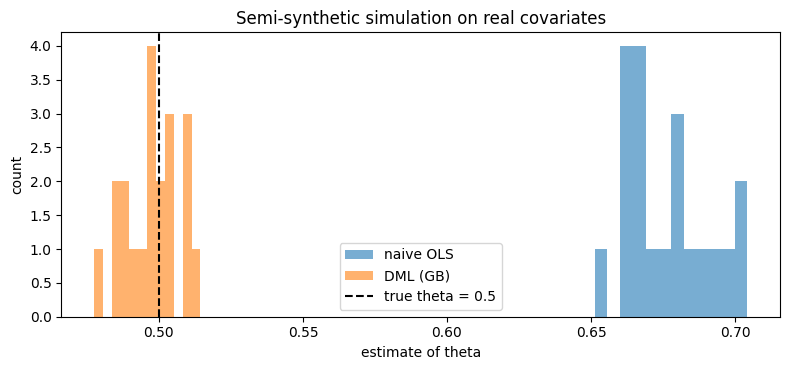

In [7]:
THETA_TRUE = 0.5
N_REP = 20
Xs = StandardScaler().fit_transform(Xc)
n = len(Xs)

def m_fun(X):   # treatment regression, confounded through X
    return 0.6 * X[:, 0] + 0.4 * np.tanh(X[:, 2]) + 0.3 * X[:, 4]

def g_fun(X):   # outcome nuisance, nonlinear in X
    return 0.8 * np.sin(X[:, 0]) + 0.5 * X[:, 1] * X[:, 2] + 0.3 * X[:, 3] ** 2

sim_rows = []
for r in range(N_REP):
    rs = np.random.default_rng(1000 + r)
    Ds = m_fun(Xs) + rs.normal(size=n)
    Ys = THETA_TRUE * Ds + g_fun(Xs) + rs.normal(size=n)
    naive_s = sm.OLS(Ys, sm.add_constant(Ds)).fit().params[1]
    dml_s = dml_plr(Ys, Ds, Xs, gb, seed=SEED + r)
    sim_rows.append(dict(naive=naive_s, dml=dml_s["theta"], se=dml_s["se"],
                         covered=dml_s["lo"] <= THETA_TRUE <= dml_s["hi"]))
sim = pd.DataFrame(sim_rows)

summary = pd.DataFrame({
    "estimator": ["Naive OLS", "DML (GB nuisances)"],
    "mean estimate": [sim.naive.mean(), sim.dml.mean()],
    "bias": [sim.naive.mean() - THETA_TRUE, sim.dml.mean() - THETA_TRUE],
    "RMSE": [np.sqrt(np.mean((sim.naive - THETA_TRUE) ** 2)), np.sqrt(np.mean((sim.dml - THETA_TRUE) ** 2))],
    "sd across reps": [sim.naive.std(), sim.dml.std()],
    "95% CI coverage": [np.nan, sim.covered.mean()],
}).round(4)
print(f"True theta = {THETA_TRUE}, replications = {N_REP}")
print(summary.to_string(index=False))
print(f"Mean DML SE across replications: {sim.se.mean():.4f}")

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(sim.naive, bins=12, alpha=0.6, label="naive OLS")
ax.hist(sim.dml, bins=12, alpha=0.6, label="DML (GB)")
ax.axvline(THETA_TRUE, c="k", ls="--", label=f"true theta = {THETA_TRUE}")
ax.set_xlabel("estimate of theta"); ax.set_ylabel("count")
ax.legend(); ax.set_title("Semi-synthetic simulation on real covariates")
plt.tight_layout(); plt.show()

## Results

- Sample: n = 20,640 census block groups. Treatment is median income (per $10k), outcome is log median house value.
- Naive OLS (no controls): theta = 0.1972, SE 0.0020, 95% CI [0.1933, 0.2012].
- OLS with the 7 controls: theta = 0.1886, SE 0.0035, 95% CI [0.1818, 0.1954].
- DML with linear nuisances: theta = 0.1889, SE 0.0035, 95% CI [0.1820, 0.1958]. Out-of-fold R^2 is only 0.505 for the outcome and 0.610 for the treatment, so the linear nuisance models are weak and this estimate essentially reproduces OLS with controls.
- **DML with gradient-boosting nuisances (main estimate):** theta = 0.0725, SE 0.0028, 95% CI [0.0671, 0.0780]. Out-of-fold R^2 is 0.835 for the outcome and 0.813 for the treatment. This implies roughly 7.5% higher house value per $10k of median income (log-linear approximation).
- Sensitivity: with 300 boosting iterations at learning rate 0.05, theta = 0.0703, SE 0.0028, 95% CI [0.0649, 0.0757]. The gradient-boosting estimate is stable to the boosting budget.
- The gap between the linear-nuisance DML (0.189) and the gradient-boosting DML (0.073) is large. The controlled association depends strongly on how the confounders are modelled, which is the main warning from this analysis.
- Simulation with true theta = 0.5 (20 replications, real covariates): naive OLS mean 0.6764 (bias +0.1764, RMSE 0.1770). DML mean 0.4978 (bias -0.0022, RMSE 0.0096), 95% CI coverage 0.95, mean estimated SE 0.0123.
- Caveats: the data are observational, so none of these numbers prove causality. The coverage figure rests on 20 replications and is imprecise. The simulated treatment and outcome equations are my own choice. The outcome is top-coded at $500k.

## Conclusions
1. **The answer depends heavily on how confounders are modelled.** Estimating the effect of median income (per $10k) on log house value in 20,640 California block groups, naive OLS gives 0.197, OLS with controls 0.189 and DML with linear nuisance models 0.189, but DML with gradient-boosting nuisance models gives 0.0725 (SE 0.0028, 95% CI [0.0671, 0.0780]). Allowing non-linear relationships with location and the other covariates removes about 60% of the apparent effect; the estimate is stable to the boosting budget (0.0703 with 300 iterations).
2. **DML works when the truth is known.** In a semi-synthetic simulation with a true effect of 0.5 (20 replications), naive OLS is biased by +0.176 while DML has bias -0.002, RMSE 0.0096 and 95% interval coverage of 0.95. Cross-fitting with flexible models recovers the effect under confounding.
3. **Flexible nuisance models explain much more.** Out-of-fold R-squared is 0.835 (outcome) and 0.813 (treatment) with boosting, against 0.505 and 0.610 with linear models, which is why the linear and flexible answers differ.
4. **This is not proof of causality.** The data are observational block-group averages; income and house values share unobserved drivers (neighbourhood quality, schools, amenities) beyond the observed covariates, and DML only removes confounding that the observed variables capture. Read 0.0725 as "the association left after flexibly adjusting for location and housing characteristics", about 7.5% more house value per $10k of median income under a log-linear approximation.
5. **Limits.** Boosting was limited to 100 iterations for run time, treatment is a block-group average and there is no instrument or experiment.

**Takeaway for the interview:** DML separates estimation of the nuisance functions from estimation of the effect, so ML can be used for confounder adjustment without invalidating the inference; but it can only adjust for what is measured, and the choice of nuisance model can move the answer a lot.